<a href="https://colab.research.google.com/github/LR-Lemon/Milestone-II/blob/main/notebooks/00_feature_engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# Part 0: Market Data Feature Engineering

## Overarching Research Question

**How can historical S&P 500 and VIX observations be transformed into informative market features that support regime identification and forward volatility forecasting?**

## Notebook Objective

This notebook prepares and evaluates market features for Model B's unsupervised regime identification and Model A's supervised volatility forecasting.

Using daily S&P 500 and CBOE VIX data from 2000–2025, the analysis constructs logarithmic returns, VIX indicators, and trailing realized volatility, skewness, and kurtosis over 5-, 10-, and 20-day windows.

The engineered features are assessed for numerical integrity, variability, and correlation before selecting five inputs for the Gaussian Hidden Markov Model (HMM).

## Notebook Structure

| Section | General Question Addressed | Figures Produced |
|---|---|---|
| **1. Environment Setup** | How is the computational environment and project repository configured? | None |
| **2. Import Required Libraries** | Which Python libraries are required for feature engineering and analysis? | None |
| **3. Load the Merged Market Dataset** | What market data are available for feature construction? | None |
| **4. Dataset Structure and Integrity** | Is the dataset complete, correctly structured, and chronologically consistent? | None |
| **5. Feature Engineering** | How can market observations be transformed into measures of returns, volatility, and return distributions? | None |
| **6. Candidate Feature Evaluation and Selection** | Which engineered features capture relevant market characteristics while limiting unnecessary redundancy? | `fig_feature_correlation` |
| **7. Final Dataset Preparation and Validation** | Are the complete and selected feature datasets valid, consistent, and ready for modeling? | None |
| **Misc — Export and Reproducibility** | How are the datasets, analytical tables, and figures preserved for subsequent analysis? | Exports `fig_feature_correlation` |

## Notebook Outputs and Integration with Models A and B

The notebook produces two validated Parquet datasets covering **6,519 trading observations from February 2000 through December 2025**.

| Output | Dimensions | Purpose |
|---|---|---|
| `market_full_features_2000_2025.parquet` | 6,519 × 23 | Complete market feature dataset for Model A, alternative specifications, and further analysis. |
| `market_hmm_features_2000_2025.parquet` | 6,519 × 7 | Selected five HMM predictors, plus `Date` and `SP500_Close`, for Model B. |

The five selected HMM predictors are `VIX_Level`, `VIX_Change`, `Realized_Vol_20D`, `Return_Skew_20D`, and `Return_Kurt_20D`.

**Model B** uses these features to identify latent market regimes and generate regime probabilities. **Model A** subsequently combines conventional market indicators with filtered probabilities produced by Model B to evaluate their contribution to forward realized-volatility forecasting.

Supporting statistical tables and the correlation heatmap are exported through the notebook's Misc section.


-------

## Section 1 - Environment Setup


This notebook is developed and executed in **Google Colab**, using the project's GitHub repository as the central source for datasets, notebooks, and supporting documentation.

To support reproducibility across the three project components, the environment is initialized by retrieving the GitHub repository and installing the required Python dependencies from a shared `requirements.txt` file.

This approach establishes a consistent software environment and standardized file paths, allowing the feature-engineering workflow to be reproduced independently and its outputs to be accessed by the subsequent modeling notebooks.

The repository version used during execution is also recorded through its Git commit identifier to support traceability of the analytical results.

### Section 1.1 - Setup Environment and Import Git Repository File Structure

In [1]:

from pathlib import Path
import subprocess
import sys

# GitHub repository configuration
REPO_URL = "https://github.com/LR-Lemon/Milestone-II.git" # ---- Can be changed to personal repository path (if others choose to clone or download repository)
PROJECT_ROOT = Path("/content/Milestone-II")

# Retrieve the project repository
if not (PROJECT_ROOT / ".git").is_dir():
    subprocess.run(
        ["git", "clone", REPO_URL, str(PROJECT_ROOT)],
        check=True
    )

# Install shared dependencies
requirements_path = PROJECT_ROOT / "requirements.txt"

if not requirements_path.is_file():
    raise FileNotFoundError(
        f"requirements.txt not found: {requirements_path}"
    )

subprocess.run(
    [sys.executable, "-m", "pip", "install",
     "-q", "-r", str(requirements_path)],
    check=True
)

# Record the repository version
commit_sha = subprocess.check_output(
    ["git", "-C", str(PROJECT_ROOT), "rev-parse", "HEAD"],
    text=True
).strip()

print("Project directory:", PROJECT_ROOT)
print("Git commit:", commit_sha)
print("Python version:", sys.version.split()[0])


Project directory: /content/Milestone-II
Git commit: e849c31d751547360fca5588a5ae25a3b2a8aa1d
Python version: 3.13.16


Library Import & Reproducibility Check

In [2]:

import importlib.metadata as metadata

packages = [
    "numpy",
    "pandas",
    "pyarrow",
    "scipy",
    "scikit-learn",
    "statsmodels",
    "hmmlearn",
    "xgboost",
    "matplotlib",
    "seaborn"
]

print("Installed package versions:\n")

for package in packages:
    try:
        version = metadata.version(package)
        print(f"{package:15} {version}")
    except metadata.PackageNotFoundError:
        print(f"{package:15} NOT INSTALLED")


Installed package versions:

numpy           2.1.3
pandas          2.2.3
pyarrow         23.0.1
scipy           1.16.3
scikit-learn    1.6.1
statsmodels     0.14.6
hmmlearn        0.3.3
xgboost         3.4.1
matplotlib      3.10.0
seaborn         0.13.2


## Section 2 - Import Required Libraries


The following Python libraries are imported to support data manipulation, feature engineering, and exploratory analysis of the merged S&P 500 and CBOE VIX dataset.

- **NumPy (`numpy`):** Supports numerical operations and mathematical transformations, including the calculation of logarithmic returns.
- **Pandas (`pandas`):** Provides the primary framework for loading, manipulating, and examining time-series data, including the calculation of rolling statistical features.
- **Matplotlib (`matplotlib.pyplot`):** Supports the visualization of market characteristics, feature distributions, and relationships between engineered variables.

Pandas display settings are configured to improve the readability of tabular results by displaying all columns and formatting numerical values consistently.

### Section 2.1 - Imports

In [3]:

# --------------------------------------------------
# 2.1 Import Required Libraries
# --------------------------------------------------

# Numerical operations
import numpy as np

# Data manipulation and feature engineering
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt

# --------------------------------------------------
# Display preferences
# --------------------------------------------------

# Display all DataFrame columns
pd.set_option("display.max_columns", None)

# Format floating-point values to four decimal places
pd.set_option(
    "display.float_format",
    lambda x: f"{x:,.4f}"
)

print("Feature engineering libraries imported successfully.")


Feature engineering libraries imported successfully.


## Section 3 - Load the Merged Market Dataset


The analysis uses the previously cleaned and merged `market_2000_2025.parquet` dataset, containing daily observations from the S&P 500 Index and CBOE Volatility Index (VIX) between January 2000 and December 2025.

The dataset was constructed by merging the two original market datasets using an inner join on trading dates, retaining only observations for which both S&P 500 and VIX information is available. The resulting dataset contains 6,539 daily observations.

As the initial data acquisition, cleaning, and merging were completed before this stage, the current notebook begins with the consolidated dataset rather than repeating those preprocessing steps.

To support reproducibility, the input dataset is loaded directly from the project's GitHub repository using the standardized directory structure established in Section 1. This eliminates the need for manual uploads to Google Colab and ensures that subsequent executions use the repository's version controlled dataset.

### Section 3.1 - Loading Dataset

In [4]:

# --------------------------------------------------
# 3.1 Load the Merged Market Dataset
# --------------------------------------------------

# Define the input dataset path
data_path = (
    PROJECT_ROOT
    / "data"
    / "merged"
    / "market_2000_2025.parquet"
)

# Verify that the input file exists
if not data_path.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {data_path}"
    )

# Load the merged S&P 500 and VIX dataset
df = pd.read_parquet(data_path)

print("Dataset loaded successfully.")
print("Source:", data_path)
print("Dataset shape:", df.shape)

# Preview the first five observations
display(df.head())


Dataset loaded successfully.
Source: /content/Milestone-II/data/merged/market_2000_2025.parquet
Dataset shape: (6539, 11)


,Date,SP500_Open,SP500_High,SP500_Low,SP500_Close,SP500_Adj_Close,SP500_Volume,VIX_Open,VIX_High,VIX_Low,VIX_Close
0,2000-01-03,"1,469.2500","1,478.0000","1,438.3600","1,455.2200","1,455.2200",931800000,24.3600,26.1500,23.9800,24.2100
1,2000-01-04,"1,455.2200","1,455.2200","1,397.4301","1,399.4200","1,399.4200",1009000000,24.9400,27.1800,24.8000,27.0100
2,2000-01-05,"1,399.4200","1,413.2700","1,377.6801","1,402.1100","1,402.1100",1085500000,27.9800,29.0000,25.8500,26.4100
3,2000-01-06,"1,402.1100","1,411.9000","1,392.1000","1,403.4500","1,403.4500",1092300000,26.6800,26.7100,24.7000,25.7300
4,2000-01-07,"1,403.4500","1,441.4700","1,400.7300","1,441.4700","1,441.4700",1225200000,25.1400,25.1700,21.7200,21.7200


## Section 4 - Inspect Dataset Structure and Integrity



Before constructing the engineered market features, the merged S&P 500 and CBOE VIX dataset is examined to verify its structure, completeness, and chronological consistency.

The data inspection includes:

- **Dataset dimensions:** Verifying the number of observations and variables contained in the merged dataset.
- **Data types:** Examining variable types to ensure that market observations are stored in appropriate numerical formats and trading dates are represented correctly.
- **Missing values:** Identifying null observations that could affect subsequent feature calculations.
- **Duplicate observations:** Checking for duplicate records and repeated trading dates that could distort time-series calculations.
- **Chronological consistency:** Confirming that observations are ordered by trading date and identifying the beginning and end of the observation period.
- **Descriptive statistics:** Examining the distribution, central tendency, and variability of the original market variables to identify potential anomalies.

These checks establish the integrity of the input dataset before feature construction. They also help distinguish potential data quality issues in the original market observations from missing values introduced by rolling-window calculations during feature engineering.

### Section 4.1 - Dataset Structure

In [5]:

# --------------------------------------------------
# 4.1 Dataset Structure
# --------------------------------------------------

# Dataset dimensions
print("Dataset shape:", df.shape)
print("Number of observations:", len(df))
print("Number of variables:", len(df.columns))

# Variable data types
print("\nVariable data types:")
display(df.dtypes.to_frame(name="Data Type"))

# Observation period
print("\nObservation period:")
print("First date:", df["Date"].min())
print("Last date:", df["Date"].max())


Dataset shape: (6539, 11)
Number of observations: 6539
Number of variables: 11

Variable data types:


,Data Type
Date,datetime64[ns]
SP500_Open,float64
SP500_High,float64
SP500_Low,float64
SP500_Close,float64
SP500_Adj_Close,float64
SP500_Volume,int64
VIX_Open,float64
VIX_High,float64
VIX_Low,float64



Observation period:
First date: 2000-01-03 00:00:00
Last date: 2025-12-31 00:00:00


### Section 4.2 - Missing Value Inspection

In [6]:

# --------------------------------------------------
# 4.2 Missing Value Inspection
# --------------------------------------------------

missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": df.isna().mean() * 100
})

print("Missing values by variable:")
display(missing_summary)

print("\nTotal missing values:", df.isna().sum().sum())


Missing values by variable:


,Missing_Count,Missing_Percent
Date,0,0.0000
SP500_Open,0,0.0000
SP500_High,0,0.0000
SP500_Low,0,0.0000
SP500_Close,0,0.0000
SP500_Adj_Close,0,0.0000
SP500_Volume,0,0.0000
VIX_Open,0,0.0000
VIX_High,0,0.0000
VIX_Low,0,0.0000



Total missing values: 0


### Section 4.3 - Duplicate Observations

In [7]:

# --------------------------------------------------
# 4.3 Duplicate Observation Inspection
# --------------------------------------------------

# Count completely duplicated records
duplicate_rows = df.duplicated().sum()

# Count repeated trading dates
duplicate_dates = df["Date"].duplicated().sum()

print("Duplicate records:", duplicate_rows)
print("Duplicate trading dates:", duplicate_dates)

# Display problematic observations, if any
if duplicate_rows > 0 or duplicate_dates > 0:
    print("\nObservations with duplicated trading dates:")
    display(
        df[df["Date"].duplicated(keep=False)]
        .sort_values("Date")
    )
else:
    print("\nNo duplicate records or trading dates detected.")


Duplicate records: 0
Duplicate trading dates: 0

No duplicate records or trading dates detected.


### Section 4.4 - Chronological Consistency

In [8]:

# --------------------------------------------------
# 4.4 Chronological Consistency
# --------------------------------------------------

# Verify chronological ordering
is_chronological = df["Date"].is_monotonic_increasing

# Check for missing trading dates in the date column
missing_dates = df["Date"].isna().sum()

# Check whether consecutive dates increase strictly
date_differences = df["Date"].diff().dropna()
invalid_intervals = (date_differences <= pd.Timedelta(0)).sum()

print("Chronologically ordered:", is_chronological)
print("Missing date values:", missing_dates)
print("Non-increasing date intervals:", invalid_intervals)

if is_chronological and missing_dates == 0 and invalid_intervals == 0:
    print("\nChronological consistency check passed.")
else:
    print("\nChronological inconsistencies detected; review before proceeding.")


Chronologically ordered: True
Missing date values: 0
Non-increasing date intervals: 0

Chronological consistency check passed.


### Section 4.5 - Discriptive Statistics

In [9]:

# --------------------------------------------------
# 4.5 Descriptive Statistics
# --------------------------------------------------

# Generate descriptive statistics for numeric variables
descriptive_stats = df.describe().T

# Rename columns for readability
descriptive_stats = descriptive_stats.rename(
    columns={
        "count": "Count",
        "mean": "Mean",
        "std": "Std_Dev",
        "min": "Minimum",
        "25%": "25th_Percentile",
        "50%": "Median",
        "75%": "75th_Percentile",
        "max": "Maximum"
    }
)

print("Descriptive statistics for the merged market dataset:")
display(descriptive_stats)


Descriptive statistics for the merged market dataset:


,Count,Mean,Minimum,25th_Percentile,Median,75th_Percentile,Maximum,Std_Dev
Date,6539,2012-12-31 14:04:31.968190976,2000-01-03 00:00:00,2006-07-05 12:00:00,2013-01-02 00:00:00,2019-07-01 12:00:00,2025-12-31 00:00:00,NaN
SP500_Open,"6,539.0000","2,268.6176",679.2800,"1,210.1250","1,527.2900","2,891.1650","6,936.0200","1,453.8762"
SP500_High,"6,539.0000","2,281.5469",695.2700,"1,217.2050","1,533.7400","2,899.4850","6,945.7700","1,460.5453"
SP500_Low,"6,539.0000","2,254.6831",666.7900,"1,202.7000","1,519.1200","2,876.7000","6,921.6001","1,446.6601"
SP500_Close,"6,539.0000","2,268.9515",676.5300,"1,210.2700","1,526.7500","2,888.0750","6,932.0498","1,454.1429"
SP500_Adj_Close,"6,539.0000","2,268.9515",676.5300,"1,210.2700","1,526.7500","2,888.0750","6,932.0498","1,454.1429"
SP500_Volume,"6,539.0000","3,418,314,009.7874",0.0000,"2,311,660,000.0000","3,529,430,000.0000","4,260,655,000.0000","11,456,230,000.0000","1,513,326,882.4533"
VIX_Open,"6,539.0000",19.9904,2.5800,14.0900,17.9100,23.3950,82.6900,8.4334
VIX_High,"6,539.0000",20.9094,9.3100,14.6700,18.7200,24.4400,89.5300,9.0212
VIX_Low,"6,539.0000",19.0632,8.5600,13.5450,17.1000,22.3750,72.7600,7.7889


In [10]:

# --------------------------------------------------
# 4.5.1 Investigation of Potential Data Anomalies
# --------------------------------------------------

# Identify zero-volume observations
zero_volume = df.loc[
    df["SP500_Volume"] == 0,
    ["Date", "SP500_Close", "SP500_Volume"]
]

print("Zero-volume observations:", len(zero_volume))
display(zero_volume)

# Examine the minimum VIX opening value
min_vix_open = df["VIX_Open"].min()

print("\nMinimum VIX opening value:", min_vix_open)

display(
    df.loc[
        df["VIX_Open"] == min_vix_open,
        ["Date", "VIX_Open", "VIX_High", "VIX_Low", "VIX_Close"]
    ]
)

# Verify whether adjusted and unadjusted closing prices match
close_identical = df["SP500_Close"].equals(
    df["SP500_Adj_Close"]
)

print("\nS&P 500 Close and Adjusted Close identical:",
      close_identical)


Zero-volume observations: 1


,Date,SP500_Close,SP500_Volume
5885,2023-05-24,"4,115.2402",0



Minimum VIX opening value: 2.58


,Date,VIX_Open,VIX_High,VIX_Low,VIX_Close
1218,2004-11-08,2.5800,14.4800,13.6800,13.8000



S&P 500 Close and Adjusted Close identical: True


### Section 4.6 - Summary of Date Integrity and Key Observations

The preliminary data inspection evaluated the structure, completeness, uniqueness, chronological ordering, and descriptive characteristics of the merged S&P 500 and CBOE VIX dataset.

**Key Observations:**

- **Dataset structure:** The dataset contains 6,539 daily observations and 11 variables, covering January 3, 2000, through December 31, 2025.
- **Data types:** The trading-date variable is stored in datetime format, while the remaining variables use appropriate numerical types.
- **Missing values:** No explicit null values were identified across the original variables.
- **Duplicate observations:** No duplicate records or repeated trading dates were detected.
- **Chronological consistency:** All observations are arranged in strictly increasing trading-date order.
- **Market characteristics:** The VIX closing level ranges from 9.14 to 82.69, reflecting substantial variation in market-implied volatility throughout the observation period.
- **Data-quality anomalies:** One zero-volume S&P 500 observation (May 24, 2023) and one inconsistent VIX opening value (November 8, 2004) were identified. The S&P 500 closing and adjusted closing prices were also found to be identical throughout the dataset.

**Implications for Feature Engineering**

The dataset demonstrates satisfactory structural integrity and is suitable for subsequent feature construction using S&P 500 closing prices and VIX closing values.

The identified anomalies affect variables not included in the selected engineered features. Accordingly, the original observations are retained without modification, while the issues are documented for reproducibility and transparency.

The absence of explicit null values in the source dataset does not eliminate the possibility of missing value encoding or anomalous entries. Furthermore, undefined values arising naturally from rolling window calculations will be examined and handled separately during feature construction.

## Section 5 - Feature Engineering

### Section 5.1 - S&P 500 Daily Logarithmic Return

Daily S&P 500 logarithmic returns are calculated using consecutive closing prices to measure proportional changes in the index between trading days.

Unlike absolute changes in index levels, logarithmic returns provide a scale-independent measure of market performance and can be aggregated across consecutive periods. They also form the basis for subsequent calculations of realized volatility, return skewness, and return kurtosis.

The logarithmic return for trading day \(t\) is defined as:

**rₜ = ln(Pₜ / Pₜ₋₁)**

Where:

- **rₜ:** Daily logarithmic return.
- **Pₜ:** S&P 500 closing price on trading day \(t\).
- **Pₜ₋₁:** S&P 500 closing price on the preceding trading day.
- **ln:** Natural logarithm.

The first observation will not have a valid logarithmic return because no preceding closing price is available within the dataset. This is an expected consequence of the calculation rather than a missing-data issue in the original observations.

In [11]:
# Calculate the daily S&P 500 log return : we shift the S&P 500 closing price series down by one observation. Making sure to provide the previous trading day's closing price for each current observation.
# while also calculating the ratio between the current opening and closing and the previous trading days closing price.
# Then applying the natural logarithm to the ratio.

# --------------------------------------------------
# 5.1 S&P 500 Daily Logarithmic Returns
# --------------------------------------------------

# Calculate daily logarithmic returns from closing prices
df["SP500_Log_Return"] = np.log(
    df["SP500_Close"] / df["SP500_Close"].shift(1)
)

# Inspect the first observations
display(
    df[["Date", "SP500_Close", "SP500_Log_Return"]].head(10)
)

# Verify the number of undefined returns
print(
    "Missing logarithmic returns:",
    df["SP500_Log_Return"].isna().sum()
)


,Date,SP500_Close,SP500_Log_Return
0,2000-01-03,"1,455.2200",NaN
1,2000-01-04,"1,399.4200",-0.0391
2,2000-01-05,"1,402.1100",0.0019
3,2000-01-06,"1,403.4500",0.0010
4,2000-01-07,"1,441.4700",0.0267
5,2000-01-10,"1,457.6000",0.0111
6,2000-01-11,"1,438.5601",-0.0131
7,2000-01-12,"1,432.2500",-0.0044
8,2000-01-13,"1,449.6801",0.0121
9,2000-01-14,"1,465.1500",0.0106


Missing logarithmic returns: 1


### Section 5.2 - Daily Change in the VIX

The CBOE Volatility Index (VIX) provides a market-based measure of expected S&P 500 volatility over approximately the next 30 calendar days, derived from option prices.

Two features are constructed to capture complementary aspects of market-implied uncertainty:

- **VIX Level (`VIX_Level`):** The daily VIX closing value, representing the prevailing level of expected market volatility.
- **VIX Change (`VIX_Change`):** The day-over-day difference in VIX closing values, measuring changes in implied volatility between consecutive trading days.

The daily change is calculated as:

\[
\Delta VIX_t = VIX_t - VIX_{t-1}
\]

Where \(VIX_t\) represents the closing level on trading day \(t\), and \(VIX_{t-1}\) represents the previous trading day's closing level.

Using both features allows the subsequent models to distinguish between the level of market-implied volatility and the direction and magnitude of its recent movement. As with logarithmic returns, the first observation of `VIX_Change` is undefined because the preceding trading-day value is unavailable.

In [12]:

# --------------------------------------------------
# 5.2 VIX Level and Daily Change
# --------------------------------------------------

# Retain the daily VIX closing level
df["VIX_Level"] = df["VIX_Close"]

# Calculate day-over-day change in VIX index points
df["VIX_Change"] = df["VIX_Close"].diff()

# Inspect the first observations
display(
    df[["Date", "VIX_Level", "VIX_Change"]].head(10)
)

# Verify undefined observations
print("Missing VIX levels:", df["VIX_Level"].isna().sum())
print("Missing VIX changes:", df["VIX_Change"].isna().sum())


,Date,VIX_Level,VIX_Change
0,2000-01-03,24.2100,NaN
1,2000-01-04,27.0100,2.8000
2,2000-01-05,26.4100,-0.6000
3,2000-01-06,25.7300,-0.6800
4,2000-01-07,21.7200,-4.0100
5,2000-01-10,21.7100,-0.0100
6,2000-01-11,22.5000,0.7900
7,2000-01-12,22.8400,0.3400
8,2000-01-13,21.7100,-1.1300
9,2000-01-14,19.6600,-2.0500


Missing VIX levels: 0
Missing VIX changes: 1


### Section 5.3 - Trailing Realized Volatility

Trailing realized volatility is calculated from historical S&P 500 logarithmic returns to measure the magnitude of recent market fluctuations.

Unlike the VIX, which represents market expectations of volatility over approximately the next 30 calendar days, trailing realized volatility measures the variability of returns observed over a preceding trading-day window.

Three rolling horizons are considered:

5-day realized volatility: Captures short-term changes in market variability.

10-day realized volatility: Captures intermediate fluctuations and volatility persistence.

20-day realized volatility: Captures broader monthly market conditions and provides an input to the primary HMM specification.

For each trading day, realized volatility is calculated as the rolling standard deviation of daily logarithmic returns, annualized using 252 trading days:

[
RV_{t,w}=\sqrt{252}\cdot \operatorname{Std}(r_{t-w+1},\ldots,r_t)
]

Where:

(RV_{t,w}) represents annualized trailing realized volatility on day (t) over a window of (w) trading days.

(r_t) represents the daily S&P 500 logarithmic return.

(w) takes values of 5, 10, or 20 trading days.

(\sqrt{252}) annualizes daily volatility using the conventional assumption of 252 trading days per year.

All calculations use current and historical returns, without incorporating future observations. The initial observations with insufficient return history naturally produce undefined rolling values, which will be handled after all engineered features have been constructed.

In [13]:

# --------------------------------------------------
# 5.3 Trailing Realized Volatility
# --------------------------------------------------

# Rolling windows in trading days
volatility_windows = [5, 10, 20]

# Annualization factor
annualization_factor = np.sqrt(252)

# Calculate trailing annualized realized volatility
for window in volatility_windows:
    df[f"Realized_Vol_{window}D"] = (
        df["SP500_Log_Return"]
        .rolling(window=window)
        .std()
        * annualization_factor
    )

# Inspect the first 25 observations
# The first observations will contain missing values because a complete 20-return window is required before realized volatility can be calculated.
#These missing values are created by the rolling-window calculation and do not represent missing observations in the original market dataset.
display(
    df[
        [
            "Date",
            "SP500_Log_Return",
            "Realized_Vol_5D",
            "Realized_Vol_10D",
            "Realized_Vol_20D"
        ]
    ].head(25)
)

# Check undefined observations
print("\nMissing values by volatility feature:")

for window in volatility_windows:
    feature = f"Realized_Vol_{window}D"
    print(f"{feature}: {df[feature].isna().sum()}")


,Date,SP500_Log_Return,Realized_Vol_5D,Realized_Vol_10D,Realized_Vol_20D
0,2000-01-03,NaN,NaN,NaN,NaN
1,2000-01-04,-0.0391,NaN,NaN,NaN
2,2000-01-05,0.0019,NaN,NaN,NaN
3,2000-01-06,0.0010,NaN,NaN,NaN
4,2000-01-07,0.0267,NaN,NaN,NaN
5,2000-01-10,0.0111,0.3865,NaN,NaN
6,2000-01-11,-0.0131,0.2333,NaN,NaN
7,2000-01-12,-0.0044,0.2435,NaN,NaN
8,2000-01-13,0.0121,0.2468,NaN,NaN
9,2000-01-14,0.0106,0.1813,NaN,NaN



Missing values by volatility feature:
Realized_Vol_5D: 5
Realized_Vol_10D: 10
Realized_Vol_20D: 20


### Section 5.4 - Rolling Return Skewness


Rolling return skewness measures the asymmetry of the distribution of recent S&P 500 logarithmic returns. Unlike realized volatility, which captures the magnitude of return fluctuations, skewness provides information about whether recent returns have exhibited a greater tendency toward unusually negative or positive outcomes.

Three historical windows are considered:

- **5-day return skewness:** Captures short-term asymmetry in recent returns.
- **10-day return skewness:** Measures asymmetry over an intermediate trading horizon.
- **20-day return skewness:** Captures broader distributional characteristics and serves as an input to the primary HMM specification.

Negative skewness indicates a distribution with a relatively longer or more pronounced left tail, while positive skewness indicates a more pronounced right tail. Values near zero suggest greater symmetry, although they do not necessarily imply a normal distribution.

Skewness is calculated using rolling windows of daily logarithmic returns, with each observation incorporating only returns available up to the corresponding trading date.

Because skewness depends on higher-order moments, estimates from shorter rolling windows may be particularly sensitive to individual extreme returns. This limitation will be considered when interpreting the engineered features.

In [14]:

# --------------------------------------------------
# 5.4 Rolling Return Skewness
# --------------------------------------------------

skewness_windows = [5, 10, 20]

# Calculate rolling skewness of daily logarithmic returns
for window in skewness_windows:
    df[f"Return_Skew_{window}D"] = (
        df["SP500_Log_Return"]
        .rolling(window=window)
        .skew()
    )

# Inspect initial observations
display(
    df[
        [
            "Date",
            "SP500_Log_Return",
            "Return_Skew_5D",
            "Return_Skew_10D",
            "Return_Skew_20D"
        ]
    ].head(25)
)

# Verify undefined observations
print("\nMissing values by skewness feature:")

for window in skewness_windows:
    feature = f"Return_Skew_{window}D"
    print(f"{feature}: {df[feature].isna().sum()}")


,Date,SP500_Log_Return,Return_Skew_5D,Return_Skew_10D,Return_Skew_20D
0,2000-01-03,NaN,NaN,NaN,NaN
1,2000-01-04,-0.0391,NaN,NaN,NaN
2,2000-01-05,0.0019,NaN,NaN,NaN
3,2000-01-06,0.0010,NaN,NaN,NaN
4,2000-01-07,0.0267,NaN,NaN,NaN
5,2000-01-10,0.0111,-1.2014,NaN,NaN
6,2000-01-11,-0.0131,0.4042,NaN,NaN
7,2000-01-12,-0.0044,0.6613,NaN,NaN
8,2000-01-13,0.0121,-0.0303,NaN,NaN
9,2000-01-14,0.0106,-0.9197,NaN,NaN



Missing values by skewness feature:
Return_Skew_5D: 5
Return_Skew_10D: 10
Return_Skew_20D: 20


### Section 5.5 - Rolling Return Kurtosis



Kurtosis provides information about the occurrence of unusually large returns
within the recent S&P 500 return distribution. It therefore complements
realized volatility and skewness by describing the extent to which recent
returns contain extreme observations.

Rolling kurtosis is calculated over the same three horizons used for realized
volatility and skewness:

- **5 trading days**, representing approximately one trading week;
- **10 trading days**, representing approximately two trading weeks; and
- **20 trading days**, representing approximately one trading month.

Pandas calculates **excess kurtosis**, where a normal distribution has an
excess kurtosis of approximately zero.

Under this convention:

- A value near **zero** indicates tail behavior broadly similar to a normal
  distribution.
- A **positive value** indicates heavier tails and a greater presence of
  extreme observations.
- A **negative value** indicates lighter tails relative to a normal
  distribution.

Using multiple horizons allows the analysis to compare the responsiveness and
stability of the kurtosis estimates. The shorter 5 day window may respond more
quickly to extreme market movements but is calculated from relatively few
observations and may therefore be less stable. The 10 and 20 day measures use
progressively more information and may provide more stable estimates.

These characteristics will be considered during feature evaluation and selection.

In [15]:
# --------------------------------------------------
# 5.5 Rolling Return Kurtosis
# --------------------------------------------------

kurtosis_windows = [5, 10, 20]

# Calculate trailing excess kurtosis
for window in kurtosis_windows:
    df[f"Return_Kurt_{window}D"] = (
        df["SP500_Log_Return"]
        .rolling(window=window)
        .kurt()
    )

# Inspect the first 25 observations
display(
    df[
        [
            "Date",
            "SP500_Log_Return",
            "Return_Kurt_5D",
            "Return_Kurt_10D",
            "Return_Kurt_20D"
        ]
    ].head(25)
)

# Verify undefined observations
print("\nMissing values by kurtosis feature:")

for window in kurtosis_windows:
    feature = f"Return_Kurt_{window}D"
    print(f"{feature}: {df[feature].isna().sum()}")


,Date,SP500_Log_Return,Return_Kurt_5D,Return_Kurt_10D,Return_Kurt_20D
0,2000-01-03,NaN,NaN,NaN,NaN
1,2000-01-04,-0.0391,NaN,NaN,NaN
2,2000-01-05,0.0019,NaN,NaN,NaN
3,2000-01-06,0.0010,NaN,NaN,NaN
4,2000-01-07,0.0267,NaN,NaN,NaN
5,2000-01-10,0.0111,2.3723,NaN,NaN
6,2000-01-11,-0.0131,0.7275,NaN,NaN
7,2000-01-12,-0.0044,0.0158,NaN,NaN
8,2000-01-13,0.0121,-0.8947,NaN,NaN
9,2000-01-14,0.0106,-1.4830,NaN,NaN



Missing values by kurtosis feature:
Return_Kurt_5D: 5
Return_Kurt_10D: 10
Return_Kurt_20D: 20


Observation:

The rolling kurtosis measures were successfully calculated across the 5-, 10-,
and 20-day horizons. As expected, the first valid observations become available
after sufficient historical returns have accumulated for each rolling window.

The initial results show that the 5-day kurtosis measure changes considerably
more sharply than the longer-window measures. This is expected because the
statistic is calculated from only five recent returns, meaning that a single
large observation can have a substantial influence on the estimated shape of
the return distribution.

The 10-day measure appears less variable, while the 20-day measure provides a
broader representation of recent tail behavior. However, these initial
observations are not sufficient to determine which horizon should be used in
the HMM.

The full distributions, variability, and relationships among the candidate
features will therefore be evaluated before selecting the final model inputs.

The three kurtosis measures are retained as candidate features at this stage.
They will later be compared in terms of their variability and correlation
with other features before the final HMM specification is selected.

### Section 5.6 - Engineered Feature Integrity

In [16]:
# --------------------------------------------------
# 5.6 Engineered Feature Integrity
# --------------------------------------------------

# Define all engineered features
engineered_features = [
    "SP500_Log_Return",
    "VIX_Level",
    "VIX_Change",
    "Realized_Vol_5D",
    "Realized_Vol_10D",
    "Realized_Vol_20D",
    "Return_Skew_5D",
    "Return_Skew_10D",
    "Return_Skew_20D",
    "Return_Kurt_5D",
    "Return_Kurt_10D",
    "Return_Kurt_20D"
]

# Summarize feature availability
feature_integrity = pd.DataFrame({
    "Data_Type": df[engineered_features].dtypes,
    "Missing_Count": df[engineered_features].isna().sum(),
    "Valid_Count": df[engineered_features].notna().sum(),
    "Infinite_Count": np.isinf(df[engineered_features]).sum()
})

print("Engineered feature integrity:")
display(feature_integrity)

# Identify the first complete-feature observation
complete_features = df[engineered_features].notna().all(axis=1)

print("\nFirst complete-feature date:",
      df.loc[complete_features, "Date"].min())

print("Complete-feature observations:",
      complete_features.sum())


Engineered feature integrity:


,Data_Type,Missing_Count,Valid_Count,Infinite_Count
SP500_Log_Return,float64,1,6538,0
VIX_Level,float64,0,6539,0
VIX_Change,float64,1,6538,0
Realized_Vol_5D,float64,5,6534,0
Realized_Vol_10D,float64,10,6529,0
Realized_Vol_20D,float64,20,6519,0
Return_Skew_5D,float64,5,6534,0
Return_Skew_10D,float64,10,6529,0
Return_Skew_20D,float64,20,6519,0
Return_Kurt_5D,float64,5,6534,0



First complete-feature date: 2000-02-01 00:00:00
Complete-feature observations: 6519


### Section 5.7 - Summary of Feature Engineering and Key Observations

**Key Observations**:

**Feature construction**: Twelve engineered variables were successfully generated, comprising logarithmic returns, two VIX measures, and nine rolling return statistics.

**Rolling-window alignment:** The 5, 10, and 20 day rolling features become available after sufficient historical observations have accumulated, beginning January 10, January 18, and February 1, 2000, respectively.

**Missing values:** The initial undefined observations are consistent with the historical data requirements of the calculations. No unexpected missing values were identified.

**Numerical integrity:** All engineered variables are stored as float64, with no infinite values detected.

**Complete feature matrix:** The dataset contains 6,519 observations with complete engineered features, covering February 1, 2000, through December 31, 2025.

**Feature characteristics:** The engineered variables capture complementary aspects of market behavior, including volatility levels, changes in implied uncertainty, historical return variability, distributional asymmetry, and excess kurtosis.

**Implications for Subsequent Modeling**

The completed feature-engineering stage establishes a consistent set of historical market indicators for the project's supervised and unsupervised learning components.

The 20 day realized volatility, skewness, and kurtosis features provide broader historical measures for the primary HMM specification in Model B, alongside VIX level and daily change. The complete collection of engineered features is retained for further exploratory analysis and supervised forecasting in Model A.

All rolling calculations use historical observations, without directly incorporating future returns. This establishes an appropriate foundation for time series prediction, although the prevention of look ahead bias must also be maintained during subsequent scaling, model estimation, and evaluation.

The initial 20 observations with incomplete feature histories will be excluded when constructing the final complete feature datasets. This exclusion preserves a consistent observation period across the selected modeling inputs.

In [17]:
# stores the names of all variables currently being considered as potential inputs to the regime-detection model.
# Keeping the feature names in a Python list makes it easier to consistently select the same variables during exploratory analysis, missing-value checks,
# correlation analysis, and later model preparation.
candidate_features = [
    "VIX_Level",
    "VIX_Change",
    "Realized_Vol_5D",
    "Realized_Vol_10D",
    "Realized_Vol_20D",
    "Return_Skew_5D",
    "Return_Skew_10D",
    "Return_Skew_20D",
    "Return_Kurt_5D",
    "Return_Kurt_10D",
    "Return_Kurt_20D"
]

# Display the candidate features in one table
display(
    df[["Date"] + candidate_features].head(25)
)

,Date,VIX_Level,VIX_Change,Realized_Vol_5D,Realized_Vol_10D,Realized_Vol_20D,Return_Skew_5D,Return_Skew_10D,Return_Skew_20D,Return_Kurt_5D,Return_Kurt_10D,Return_Kurt_20D
0,2000-01-03,24.2100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2000-01-04,27.0100,2.8000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2000-01-05,26.4100,-0.6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2000-01-06,25.7300,-0.6800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2000-01-07,21.7200,-4.0100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2000-01-10,21.7100,-0.0100,0.3865,NaN,NaN,-1.2014,NaN,NaN,2.3723,NaN,NaN
6,2000-01-11,22.5000,0.7900,0.2333,NaN,NaN,0.4042,NaN,NaN,0.7275,NaN,NaN
7,2000-01-12,22.8400,0.3400,0.2435,NaN,NaN,0.6613,NaN,NaN,0.0158,NaN,NaN
8,2000-01-13,21.7100,-1.1300,0.2468,NaN,NaN,-0.0303,NaN,NaN,-0.8947,NaN,NaN
9,2000-01-14,19.6600,-2.0500,0.1813,NaN,NaN,-0.9197,NaN,NaN,-1.4830,NaN,NaN


## Section 6 - Candidate Feature Evaluation and Selection



Following feature construction, the engineered market indicators are evaluated to assess their suitability for subsequent modeling, particularly the primary Hidden Markov Model (HMM) used in Model B.

Although the complete feature set captures multiple dimensions of market conditions, including implied volatility, historical return variability, asymmetry, and tail characteristics, not all candidate variables necessarily provide distinct information. Features derived over different rolling windows may exhibit substantial correlation, potentially introducing redundancy into the model specification.

The feature-evaluation process includes:

- **Candidate feature review:** Identifying the complete set of engineered variables available for subsequent analysis.
- **Missing-value verification:** Confirming that undefined observations arise from the initial rolling-window requirements rather than unexpected data-quality issues.
- **Complete-feature dataset construction:** Retaining observations with valid values across all candidate features to establish a consistent modeling sample.
- **Descriptive statistics and variability:** Examining feature distributions, ranges, and dispersion to assess differences across historical windows.
- **Correlation analysis:** Evaluating linear relationships between candidate features to identify potential redundancy.
- **HMM feature selection:** Selecting a parsimonious combination of market indicators that captures complementary dimensions of market conditions while limiting unnecessary feature overlap.

The complete engineered feature set will be retained for Model A and alternative specifications, while a selected subset will serve as the input for Model B's primary HMM specification.

Feature selection at this stage is based on exploratory characteristics and economic interpretation. The predictive or statistical effectiveness of the selected inputs will be evaluated separately during model development.

### Section 6.1 - Review Candidate Features

In [18]:
# --------------------------------------------------
# 6.1 Review Candidate Features
# --------------------------------------------------

candidate_features = [
    "VIX_Level",
    "VIX_Change",
    "Realized_Vol_5D",
    "Realized_Vol_10D",
    "Realized_Vol_20D",
    "Return_Skew_5D",
    "Return_Skew_10D",
    "Return_Skew_20D",
    "Return_Kurt_5D",
    "Return_Kurt_10D",
    "Return_Kurt_20D"
]

# Verify that all candidate features exist
missing_columns = [
    feature for feature in candidate_features
    if feature not in df.columns
]

if missing_columns:
    raise KeyError(f"Missing candidate features: {missing_columns}")

print("Number of candidate features:", len(candidate_features))
print("\nCandidate feature list:")

for feature in candidate_features:
    print("-", feature)


Number of candidate features: 11

Candidate feature list:
- VIX_Level
- VIX_Change
- Realized_Vol_5D
- Realized_Vol_10D
- Realized_Vol_20D
- Return_Skew_5D
- Return_Skew_10D
- Return_Skew_20D
- Return_Kurt_5D
- Return_Kurt_10D
- Return_Kurt_20D


### Section 6.2 - Complete Feature Dataset Construction

In [19]:
# --------------------------------------------------
# 6.2 Construct Complete-Feature Dataset
# --------------------------------------------------

# Retain observations with complete candidate features
df_features = (
    df.dropna(subset=candidate_features)
    .copy()
    .reset_index(drop=True)
)

# Verify the resulting dataset
print("Original observations:", len(df))
print("Complete-feature observations:", len(df_features))
print("Observations excluded:", len(df) - len(df_features))

print("\nComplete-feature observation period:")
print("First date:", df_features["Date"].min())
print("Last date:", df_features["Date"].max())

print("\nRemaining missing candidate values:")
print(df_features[candidate_features].isna().sum().sum())


Original observations: 6539
Complete-feature observations: 6519
Observations excluded: 20

Complete-feature observation period:
First date: 2000-02-01 00:00:00
Last date: 2025-12-31 00:00:00

Remaining missing candidate values:
0


### Section 6.3 - Descriptive Statistics and Feature Variability

Descriptive statistics are calculated for the 11 candidate market features to examine their distributional characteristics, numerical ranges, and variability over the complete observation period.

This analysis supports the evaluation of candidate features before selecting the primary HMM inputs.

The analysis focuses on:

1- Central tendency: Comparing means and medians to examine typical feature values.

2- Dispersion: Evaluating standard deviations and numerical ranges to assess differences in feature variability.

3- Distributional characteristics: Identifying potentially asymmetric distributions and extreme observations that may influence model estimation.

4- Rolling window differences: Comparing the 5, 10, and 20 day measures of realized volatility, skewness, and kurtosis.

5- Modeling implications: Identifying differences in numerical scales and potentially unstable features that should be considered during feature selection and standardization.

The objective is not to determine which features are most predictive at this stage, but to assess their statistical characteristics and suitability for subsequent unsupervised modeling.

Feature standardization will be performed within Model B using the appropriate training data to avoid introducing look ahead bias.

In [20]:
# --------------------------------------------------
# 6.3 Descriptive Statistics and Feature Variability
# --------------------------------------------------

# Calculate descriptive statistics
feature_stats = (
    df_features[candidate_features]
    .describe()
    .T
)

# Improve column readability
feature_stats = feature_stats.rename(
    columns={
        "count": "Count",
        "mean": "Mean",
        "std": "Std_Dev",
        "min": "Minimum",
        "25%": "25th_Percentile",
        "50%": "Median",
        "75%": "75th_Percentile",
        "max": "Maximum"
    }
)

print("Descriptive statistics for candidate features:")
display(feature_stats)


Descriptive statistics for candidate features:


,Count,Mean,Std_Dev,Minimum,25th_Percentile,Median,75th_Percentile,Maximum
VIX_Level,"6,519.0000",19.8278,8.3777,9.1400,13.9800,17.7500,23.2100,82.6900
VIX_Change,"6,519.0000",-0.0015,1.8147,-18.7100,-0.7200,-0.0900,0.5900,24.8600
Realized_Vol_5D,"6,519.0000",0.1555,0.1224,0.0084,0.0815,0.1247,0.1909,1.5229
Realized_Vol_10D,"6,519.0000",0.1605,0.1131,0.0232,0.0915,0.1319,0.1926,1.1967
Realized_Vol_20D,"6,519.0000",0.1635,0.1065,0.0328,0.0975,0.1370,0.1980,0.9790
Return_Skew_5D,"6,519.0000",0.0212,0.9275,-2.2091,-0.6143,0.0283,0.6590,2.2026
Return_Skew_10D,"6,519.0000",-0.0191,0.7491,-2.8308,-0.5155,-0.0219,0.4732,2.7891
Return_Skew_20D,"6,519.0000",-0.0919,0.6408,-3.1657,-0.4644,-0.0946,0.3090,2.5151
Return_Kurt_5D,"6,519.0000",0.0965,2.0054,-3.3285,-1.6557,0.0349,1.6739,4.8986
Return_Kurt_10D,"6,519.0000",0.2568,1.4770,-2.2077,-0.8010,-0.0810,0.9653,8.5845


In [21]:

# --------------------------------------------------
# 6.3.1 Percentage Changes Across Rolling Windows
# --------------------------------------------------

feature_groups = {
    "Realized Volatility": "Realized_Vol",
    "Return Skewness": "Return_Skew",
    "Return Kurtosis": "Return_Kurt"
}

comparison_rows = []

for group, prefix in feature_groups.items():
    for statistic, column in {
        "Mean": "Mean",
        "Standard Deviation": "Std_Dev",
        "Maximum": "Maximum"
    }.items():

        values = {
            window: feature_stats.loc[
                f"{prefix}_{window}D", column
            ]
            for window in [5, 10, 20]
        }

        def percentage_change(old, new):
            if np.isclose(old, 0):
                return np.nan
            return ((new - old) / abs(old)) * 100

        comparison_rows.append({
            "Feature Group": group,
            "Statistic": statistic,
            "5-Day": values[5],
            "10-Day": values[10],
            "20-Day": values[20],
            "5D to 10D (%)": percentage_change(
                values[5], values[10]
            ),
            "10D to 20D (%)": percentage_change(
                values[10], values[20]
            ),
            "5D to 20D (%)": percentage_change(
                values[5], values[20]
            )
        })

window_comparison = pd.DataFrame(comparison_rows)

display(
    window_comparison.style.format({
        "5-Day": "{:.4f}",
        "10-Day": "{:.4f}",
        "20-Day": "{:.4f}",
        "5D to 10D (%)": "{:+.2f}%",
        "10D to 20D (%)": "{:+.2f}%",
        "5D to 20D (%)": "{:+.2f}%"
    })
)


,Feature Group,Statistic,5-Day,10-Day,20-Day,5D to 10D (%),10D to 20D (%),5D to 20D (%)
0,Realized Volatility,Mean,0.1555,0.1605,0.1635,+3.23%,+1.88%,+5.17%
1,Realized Volatility,Standard Deviation,0.1224,0.1131,0.1065,-7.61%,-5.79%,-12.97%
2,Realized Volatility,Maximum,1.5229,1.1967,0.9790,-21.42%,-18.19%,-35.72%
3,Return Skewness,Mean,0.0212,-0.0191,-0.0919,-190.21%,-381.03%,-533.95%
4,Return Skewness,Standard Deviation,0.9275,0.7491,0.6408,-19.23%,-14.47%,-30.92%
5,Return Skewness,Maximum,2.2026,2.7891,2.5151,+26.63%,-9.82%,+14.19%
6,Return Kurtosis,Mean,0.0965,0.2568,0.4727,+166.25%,+84.06%,+390.06%
7,Return Kurtosis,Standard Deviation,2.0054,1.4770,1.4779,-26.35%,+0.06%,-26.31%
8,Return Kurtosis,Maximum,4.8986,8.5845,12.4479,+75.24%,+45.00%,+154.11%


Key observations:
- Mean realized volatility increases slightly from 15.55% for the 5-day window to 16.35% for the 20-day window.
- Standard deviation decreases from 12.24 percentage points to 10.65 percentage points as the window length increases.
- The maximum observed annualized volatility falls from 152.29% (5-day) to 97.90% (20-day).

These findings are consistent with longer rolling windows producing smoother historical volatility measures, while shorter windows respond more sharply to recent market movements.

**The descriptive results highlight three considerations:**
- **Different feature scales:** VIX levels, daily VIX changes, annualized volatility, and unitless higher order moments have substantially different numerical ranges. This supports the need for training-fitted standardization in Model B.
-** Rolling-window sensitivity:** The 5 day features generally exhibit greater variability, particularly realized volatility and skewness.
- **Potential redundancy:** The three realized volatility windows describe related underlying market characteristics. Their degree of overlap must be evaluated through correlation analysis before finalizing the HMM feature subset.

### Section 6.4 - Candidate Feature Correlation Analysis

A Pearson correlation analysis is conducted to examine the linear relationships among the 11 candidate market features and identify potential redundancy before selecting the primary Hidden Markov Model (HMM) inputs.

Although the engineered variables represent different dimensions of market conditions, features calculated over overlapping rolling windows may capture similar information. Examining their correlations helps assess whether a smaller feature subset can preserve complementary market characteristics while limiting unnecessary overlap.

The analysis focuses on:

Within-group correlations: Examining relationships among the 5-, 10-, and 20-day measures of realized volatility, return skewness, and return kurtosis.

Cross-group correlations: Evaluating relationships between VIX measures and historical return characteristics.

Feature redundancy: Identifying strongly correlated variables that may provide overlapping information to the HMM.

Feature-selection implications: Assessing which combinations of features may offer a more parsimonious representation of market conditions.

Pearson correlation coefficients range from −1 to +1, where values closer to either extreme indicate stronger linear relationships. Correlations near zero indicate weak linear association but do not necessarily imply statistical independence.

The analysis is exploratory and does not independently determine the optimal feature specification. The final selection will also consider economic interpretation, historical-window sensitivity, and the subsequent evaluation of Model B.

Pearson Correlation Matrix:


,VIX_Level,VIX_Change,Realized_Vol_5D,Realized_Vol_10D,Realized_Vol_20D,Return_Skew_5D,Return_Skew_10D,Return_Skew_20D,Return_Kurt_5D,Return_Kurt_10D,Return_Kurt_20D
VIX_Level,1.0000,0.1083,0.8037,0.8598,0.8725,-0.0155,-0.0040,0.0146,-0.0354,-0.0643,-0.0853
VIX_Change,0.1083,1.0000,-0.0399,-0.0331,-0.0389,-0.0234,-0.0409,-0.0584,-0.0039,0.0254,0.0342
Realized_Vol_5D,0.8037,-0.0399,1.0000,0.9085,0.8247,-0.0061,-0.0112,0.0056,-0.0120,-0.0597,-0.0438
Realized_Vol_10D,0.8598,-0.0331,0.9085,1.0000,0.9289,-0.0055,-0.0010,0.0237,-0.0368,-0.0399,-0.0560
Realized_Vol_20D,0.8725,-0.0389,0.8247,0.9289,1.0000,0.0082,0.0292,0.0461,-0.0412,-0.0642,-0.0639
Return_Skew_5D,-0.0155,-0.0234,-0.0061,-0.0055,0.0082,1.0000,0.4779,0.2618,0.0161,-0.0537,-0.0496
Return_Skew_10D,-0.0040,-0.0409,-0.0112,-0.0010,0.0292,0.4779,1.0000,0.5726,0.0073,-0.0367,-0.1314
Return_Skew_20D,0.0146,-0.0584,0.0056,0.0237,0.0461,0.2618,0.5726,1.0000,-0.0005,-0.0907,-0.2649
Return_Kurt_5D,-0.0354,-0.0039,-0.0120,-0.0368,-0.0412,0.0161,0.0073,-0.0005,1.0000,0.3198,0.1812
Return_Kurt_10D,-0.0643,0.0254,-0.0597,-0.0399,-0.0642,-0.0537,-0.0367,-0.0907,0.3198,1.0000,0.5458


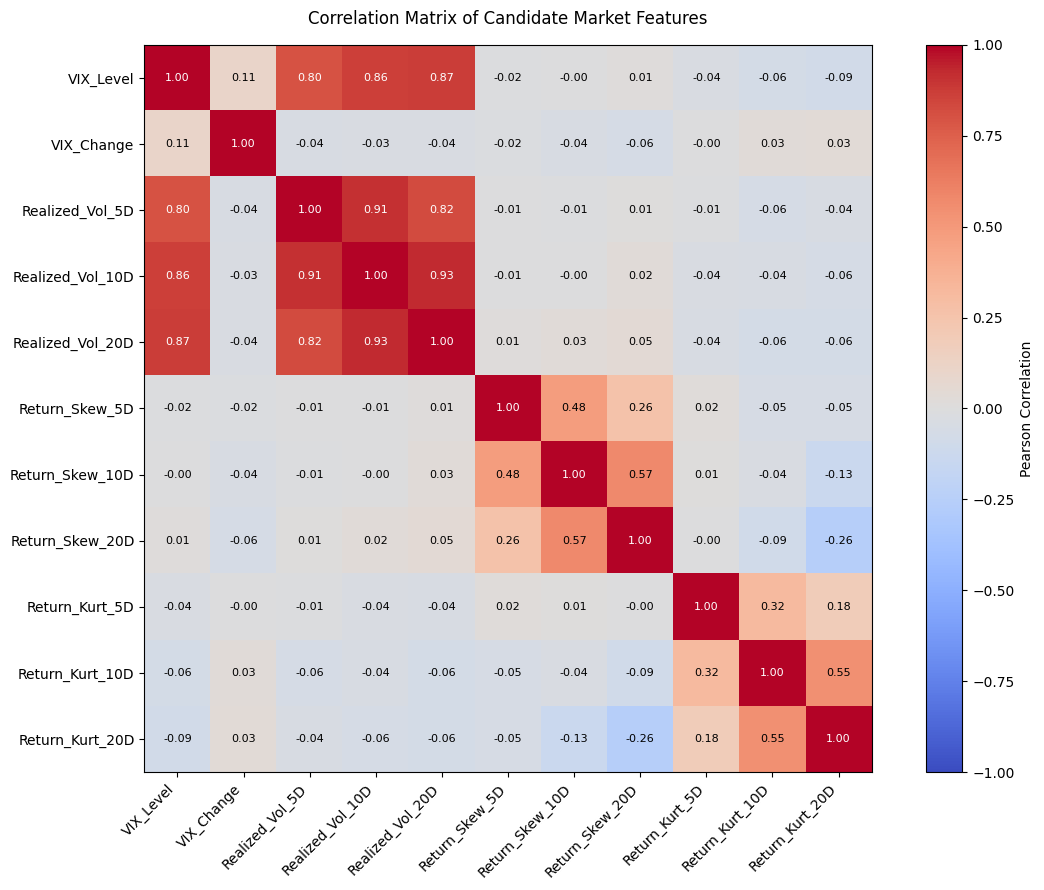

In [22]:

# --------------------------------------------------
# 6.4 Candidate Feature Correlation Analysis
# --------------------------------------------------

# Calculate Pearson correlation matrix
feature_corr = df_features[candidate_features].corr(
    method="pearson"
)

# Display numerical correlation matrix
print("Pearson Correlation Matrix:")
display(feature_corr.round(4))

# --------------------------------------------------
# Correlation Heatmap
# --------------------------------------------------

# Create and retain figure and axes objects
fig_feature_correlation, ax_feature_correlation = plt.subplots(
    figsize=(12, 9)
)

# Plot correlation matrix
im_feature_correlation = ax_feature_correlation.imshow(
    feature_corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

# Configure axis labels
ax_feature_correlation.set_xticks(
    np.arange(len(candidate_features))
)

ax_feature_correlation.set_yticks(
    np.arange(len(candidate_features))
)

ax_feature_correlation.set_xticklabels(
    candidate_features,
    rotation=45,
    ha="right"
)

ax_feature_correlation.set_yticklabels(
    candidate_features
)

# Add correlation coefficients
for i in range(len(candidate_features)):
    for j in range(len(candidate_features)):

        value = feature_corr.iloc[i, j]

        ax_feature_correlation.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if abs(value) >= 0.65 else "black"
        )

# Add color bar
fig_feature_correlation.colorbar(
    im_feature_correlation,
    ax=ax_feature_correlation,
    label="Pearson Correlation"
)

# Add title
ax_feature_correlation.set_title(
    "Correlation Matrix of Candidate Market Features",
    pad=15
)

# Optimize layout
fig_feature_correlation.tight_layout()

# Display visualization
plt.show()


In [23]:
# --------------------------------------------------
# 6.4.1 Strongest Pairwise Feature Correlations
# --------------------------------------------------

upper_triangle = np.triu(
    np.ones(feature_corr.shape, dtype=bool),
    k=1
)

correlation_pairs = (
    feature_corr.where(upper_triangle)
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    "Feature_1",
    "Feature_2",
    "Correlation"
]

correlation_pairs["Absolute_Correlation"] = (
    correlation_pairs["Correlation"].abs()
)

correlation_pairs = (
    correlation_pairs
    .sort_values("Absolute_Correlation", ascending=False)
    .reset_index(drop=True)
)

print("Top 10 strongest feature correlations:")
display(correlation_pairs.head(10))


Top 10 strongest feature correlations:


,Feature_1,Feature_2,Correlation,Absolute_Correlation
0,Realized_Vol_10D,Realized_Vol_20D,0.9289,0.9289
1,Realized_Vol_5D,Realized_Vol_10D,0.9085,0.9085
2,VIX_Level,Realized_Vol_20D,0.8725,0.8725
3,VIX_Level,Realized_Vol_10D,0.8598,0.8598
4,Realized_Vol_5D,Realized_Vol_20D,0.8247,0.8247
5,VIX_Level,Realized_Vol_5D,0.8037,0.8037
6,Return_Skew_10D,Return_Skew_20D,0.5726,0.5726
7,Return_Kurt_10D,Return_Kurt_20D,0.5458,0.5458
8,Return_Skew_5D,Return_Skew_10D,0.4779,0.4779
9,Return_Kurt_5D,Return_Kurt_10D,0.3198,0.3198


Key Observations:

1. Realized volatility features exhibit substantial redundancy. The 10 day and 20 day measures have the highest correlation (0.9289), followed by the 5 day and 10 day measures (0.9085). This supports our decision to consider a single realized volatility horizon for the primary HMM.

2. VIX Level and realized volatility capture overlapping information. The correlation between VIX_Level and Realized_Vol_20D is 0.8725. Although both measure volatility conditions, the VIX reflects forward looking market expectations, whereas realized volatility measures historical fluctuations. Retaining both is defensible, but their incremental contributions should be investigated during Model B evaluation.

3. Skewness and kurtosis exhibit weaker cross-window correlations. For example, 10 day and 20 day skewness have a correlation of 0.5726, while 10 day and 20-day kurtosis have a correlation of 0.5458. These measures may provide complementary historical information, although correlation alone cannot determine their usefulness for regime identification.

### Section 6.5 - Selection of HMM Input Features

Following the descriptive and correlation analyses, a reduced feature set is selected for the primary Gaussian Hidden Markov Model (HMM).

The objective is to construct a parsimonious representation of market conditions that captures different dimensions of volatility behavior while limiting unnecessary overlap among highly correlated variables.

The selection is informed by three considerations:

- **Economic relevance:** Retaining indicators that represent distinct aspects of market uncertainty and historical return behavior.
- **Feature redundancy:** Limiting the inclusion of multiple rolling-window measures that capture strongly overlapping information.
- **Historical-window stability:** Favoring 20 day return statistics for the primary specification to represent broader market conditions and reduce sensitivity to isolated daily fluctuations.

The five selected features are:

| Feature | Market characteristic represented | Selection rationale |
|---|---|---|
| `VIX_Level` | Implied market volatility | Captures the prevailing level of market-implied uncertainty |
| `VIX_Change` | Changes in implied volatility | Represents short-term movements in market uncertainty |
| `Realized_Vol_20D` | Historical volatility | Captures broader realized market fluctuations |
| `Return_Skew_20D` | Return asymmetry | Represents historical imbalances between positive and negative returns |
| `Return_Kurt_20D` | Return tail characteristics | Captures the prominence of extreme historical returns |

The correlation analysis provides additional support for this specification. In particular, the realized-volatility measures exhibit strong correlations, including 0.9289 between the 10 day and 20 day measures, suggesting that incorporating all three horizons could introduce substantial redundancy.

Although `VIX_Level` and `Realized_Vol_20D` are also strongly correlated (0.8725), both are retained because they represent conceptually different measures of market volatility: option-implied expectations and historically observed fluctuations.

The selected feature set is intended to balance interpretability, complementary market information, and model complexity. Its suitability will be further assessed through model evaluation and sensitivity analysis in Part 1 (unsupervised learning), rather than treating this exploratory selection as definitive evidence of optimality.

In [24]:
# --------------------------------------------------
# 6.5 Selection of HMM Input Features
# --------------------------------------------------

hmm_features = [
    "VIX_Level",
    "VIX_Change",
    "Realized_Vol_20D",
    "Return_Skew_20D",
    "Return_Kurt_20D"
]

# Verify that selected features exist
assert all(
    feature in df_features.columns
    for feature in hmm_features
), "One or more selected HMM features are missing."

# Inspect the selected feature subset
print("Number of selected HMM features:", len(hmm_features))
print("\nSelected HMM features:")

for feature in hmm_features:
    print("-", feature)

print("\nSelected feature preview:")
display(
    df_features[
        ["Date", "SP500_Close"] + hmm_features
    ].head()
)


Number of selected HMM features: 5

Selected HMM features:
- VIX_Level
- VIX_Change
- Realized_Vol_20D
- Return_Skew_20D
- Return_Kurt_20D

Selected feature preview:


,Date,SP500_Close,VIX_Level,VIX_Change,Realized_Vol_20D,Return_Skew_20D,Return_Kurt_20D
0,2000-02-01,"1,409.2800",23.4500,-1.5000,0.2636,-0.5230,0.4541
1,2000-02-02,"1,409.1200",23.1200,-0.3300,0.2233,-0.2181,0.5606
2,2000-02-03,"1,424.9700",22.0100,-1.1100,0.2266,-0.2915,0.3915
3,2000-02-04,"1,424.3700",21.5400,-0.4700,0.2266,-0.2753,0.3819
4,2000-02-07,"1,424.2400",22.7900,1.2500,0.2048,-0.5036,0.8049


### Section 6.6 - Summary of Candidate Feature Evaluation and Selection

The candidate feature evaluation examined the statistical characteristics and relationships of the engineered market indicators to establish an interpretable and parsimonious input specification for the primary Hidden Markov Model (HMM).

Activities performed:


*   Reviewed the 11 engineered candidate features, excluding daily logarithmic returns as an intermediate calculation.

*   Constructed a complete-feature dataset by excluding the initial 20 observations with insufficient rolling-window histories.
*   Evaluated descriptive statistics, variability, and percentage differences across the 5, 10, and 20day rolling windows.

*   Examined pairwise Pearson correlations to identify potentially redundant information.

*   Selected five market features representing complementary dimensions of implied volatility, historical volatility, return asymmetry, and tail characteristics.

**Key observations:**

**1- Complete-feature dataset:** The analytical sample contains 6,519 observations spanning February 1, 2000, through December 31, 2025, with no missing candidate-feature values.

**2- Rolling-window variability:** Shorter-window realized volatility and skewness exhibit greater variability than their longer-window counterparts. The 20-day features provide broader historical measures, although their usefulness for regime identification requires subsequent evaluation.

**3- Volatility correlations:** The 10-day and 20-day realized volatility measures exhibit a strong positive correlation (0.9289), indicating substantial overlap.

**4- Implied versus realized volatility:** VIX Level and 20-day realized volatility are also strongly correlated (0.8725), but represent conceptually different sources of market information.

**5- Complementary characteristics:** VIX Change, return skewness, and return kurtosis exhibit relatively weak linear correlations with volatility-level measures, suggesting that they capture additional dimensions of market behavior.

**6- Selected HMM inputs:** The primary specification retains VIX_Level, VIX_Change, Realized_Vol_20D, Return_Skew_20D, and Return_Kurt_20D.

**Implications for Subsequent Modeling**

The selected feature specification balances economic interpretation, historical-window consistency, and model parsimony. Using one historical horizon for realized volatility, skewness, and kurtosis limits unnecessary feature proliferation while preserving measures of distinct market characteristics.

The five selected variables will serve as the primary inputs for Model B, while the complete set of 11 candidate market indicators will remain available for Model A and alternative model specifications.

Feature selection in this notebook is exploratory. Its effectiveness will be assessed during Model B's estimation and sensitivity analysis, with feature standardization fitted on the training period to preserve the integrity of subsequent out-of-sample evaluation.

## Section 7 - Final Dataset Preparation and Validation

Following feature engineering and candidate feature selection, the analytical datasets are prepared for subsequent supervised and unsupervised modeling.

Two datasets are constructed to support the different requirements of Model A and Model B. Both datasets are derived from the same complete-feature observations, ensuring consistent trading-date coverage and alignment across modeling stages.

The preparation and validation process includes:

Full engineered feature dataset: Retaining the original market variables and engineered features for exploratory analysis, supervised volatility forecasting, and alternative model specifications.

Selected HMM feature dataset: Constructing a reduced dataset containing the five selected HMM predictors, together with trading dates and S&P 500 closing prices for reference.

Structural validation: Verifying dataset dimensions, column names, and observation periods.

Numerical integrity: Checking for missing and infinite values in the final modeling features.

Temporal alignment: Confirming that the datasets contain matching trading dates in the same chronological order.

No feature standardization is applied at this stage. Scaling and other model-specific transformations will be performed within the corresponding modeling notebooks using the appropriate training data to avoid introducing look-ahead bias.

The validated datasets will subsequently be exported in Parquet format in the final Misc — Export and Reproducibility section.

In [25]:

# --------------------------------------------------
# 7.1 Prepare Final Modeling Datasets
# --------------------------------------------------

# Full engineered feature dataset
df_full_features = df_features.copy()

# Selected HMM feature dataset
hmm_output_columns = [
    "Date",
    "SP500_Close"
] + hmm_features

df_hmm_features = df_features[
    hmm_output_columns
].copy()

# --------------------------------------------------
# Preliminary verification
# --------------------------------------------------

print("Full engineered feature dataset:")
print("Shape:", df_full_features.shape)

print("\nSelected HMM feature dataset:")
print("Shape:", df_hmm_features.shape)

print("\nSelected HMM dataset columns:")
print(df_hmm_features.columns.tolist())

print("\nHMM dataset preview:")
display(df_hmm_features.head())


Full engineered feature dataset:
Shape: (6519, 23)

Selected HMM feature dataset:
Shape: (6519, 7)

Selected HMM dataset columns:
['Date', 'SP500_Close', 'VIX_Level', 'VIX_Change', 'Realized_Vol_20D', 'Return_Skew_20D', 'Return_Kurt_20D']

HMM dataset preview:


,Date,SP500_Close,VIX_Level,VIX_Change,Realized_Vol_20D,Return_Skew_20D,Return_Kurt_20D
0,2000-02-01,"1,409.2800",23.4500,-1.5000,0.2636,-0.5230,0.4541
1,2000-02-02,"1,409.1200",23.1200,-0.3300,0.2233,-0.2181,0.5606
2,2000-02-03,"1,424.9700",22.0100,-1.1100,0.2266,-0.2915,0.3915
3,2000-02-04,"1,424.3700",21.5400,-0.4700,0.2266,-0.2753,0.3819
4,2000-02-07,"1,424.2400",22.7900,1.2500,0.2048,-0.5036,0.8049


### Section 7.2 - Final Dataset Integrity and Temporal Alignment

The prepared datasets are subjected to a final validation to confirm their structural consistency, numerical integrity, and chronological alignment before use in the subsequent modeling stages.

The validation includes:

Dataset dimensions: Confirming that both outputs contain the expected number of observations and variables.

Missing and infinite values: Verifying that all final modeling features contain valid numerical observations.

Date integrity: Checking for duplicate trading dates and confirming chronological ordering.

Temporal alignment: Ensuring that the full engineered dataset and selected HMM dataset contain identical trading dates in the same order.

Feature consistency: Verifying that the selected HMM feature values match their corresponding columns in the full engineered dataset.

These checks ensure that both datasets originate from the same complete-feature sample and can be integrated consistently with subsequent model outputs.

The validation focuses on dataset preparation; model-specific preprocessing, including feature standardization and chronological train-test splitting, will be performed separately in Parts 1 (unsupervised learning) and 2 (supervised learning).

In [26]:
# --------------------------------------------------
# 7.2 Final Dataset Integrity and Temporal Alignment
# --------------------------------------------------

# 1. Structural validation
assert df_full_features.shape == (6519, 23)
assert df_hmm_features.shape == (6519, 7)

# 2. Missing-value validation
assert df_full_features.isna().sum().sum() == 0
assert df_hmm_features.isna().sum().sum() == 0

# 3. Infinite-value validation
assert np.isfinite(
    df_full_features.select_dtypes(include="number").to_numpy()
).all()

assert np.isfinite(
    df_hmm_features[hmm_features].to_numpy()
).all()

# 4. Date integrity
for dataset in [df_full_features, df_hmm_features]:
    assert dataset["Date"].is_monotonic_increasing
    assert not dataset["Date"].duplicated().any()

# 5. Temporal alignment
assert df_full_features["Date"].equals(
    df_hmm_features["Date"]
)

# 6. Selected feature consistency
pd.testing.assert_frame_equal(
    df_full_features[hmm_features],
    df_hmm_features[hmm_features]
)

print("Final dataset integrity checks passed.")

print("\nFull engineered dataset:", df_full_features.shape)
print("Selected HMM dataset:", df_hmm_features.shape)

print("\nObservation period:")
print("Start:", df_full_features["Date"].min())
print("End:", df_full_features["Date"].max())

print("\nBoth datasets have identical trading-date coverage.")

Final dataset integrity checks passed.

Full engineered dataset: (6519, 23)
Selected HMM dataset: (6519, 7)

Observation period:
Start: 2000-02-01 00:00:00
End: 2025-12-31 00:00:00

Both datasets have identical trading-date coverage.


### Section 7.3 - Summary of Final Dataset Preparation and Validation

The final dataset preparation stage constructed and validated two analytical datasets to support the subsequent supervised and unsupervised modeling components.

**Activities Performed:**

- Constructed the full engineered feature dataset by retaining the original market variables and all engineered features.
- Prepared the selected HMM dataset using five market predictors and two reference variables.
- Verified dataset dimensions, missing values, numerical finiteness, and chronological integrity.
- Confirmed that both datasets contain identical trading dates and that selected HMM feature values match their corresponding variables in the full engineered dataset.

**Key Observations:**

1. **Full Engineered Dataset:** Contains 6,519 observations and 23 variables, comprising 11 original market variables and 12 engineered features.
2. **Selected HMM Dataset:** Contains 6,519 observations and 7 variables, including five selected HMM predictors, `Date`, and `SP500_Close`.
3. **Observation Period:** Both datasets cover February 1, 2000, through December 31, 2025.
4. **Data Completeness:** No missing or infinite values were identified in either finalized dataset.
5. **Temporal Alignment:** Both datasets contain identical trading-date sequences, with no duplicate dates or chronological inconsistencies.
6. **Feature Consistency:** The five selected HMM predictors retain identical values across both datasets.

**Implications for Subsequent Modeling**

The validated datasets provide a consistent foundation for the remaining project components. The complete engineered dataset preserves the broader market feature space for Model A, while the reduced dataset provides the selected inputs for Model B.

No feature standardization or model-specific transformations have been applied at this stage. These operations will be conducted separately during model estimation, using appropriate training-period information to avoid look-ahead bias.

The datasets are therefore ready for export and subsequent modeling.

--------------------------------------------------------------------------------

## Misc - Export and Reproducibility

### Misc.1 - Export Final Engineered Datasets

The two validated feature datasets are exported in Parquet format to support subsequent modeling and reproducibility.

Parquet is used because it preserves column names, numerical data types, and datetime representations while providing efficient storage for structured market data.

The export process includes:

Full engineered feature dataset: Saving the complete dataset containing the original market variables and all engineered features for subsequent supervised modeling and additional analysis.

Selected HMM feature dataset: Saving the reduced dataset containing the five selected HMM predictors and reference variables for Model B.

File verification: Confirming that both output files are created successfully in the designated repository directory.

Data integrity verification: Reading the exported files back into memory and comparing them with the original DataFrames to ensure that no information was altered during serialization.

Both datasets are stored in the data/engineered_features/ directory, following the project's standardized GitHub repository structure.

In [27]:
# --------------------------------------------------
# Misc.1 Export and Verify Final Engineered Datasets
# --------------------------------------------------

# Define export directory
FEATURE_OUTPUT_DIR = PROJECT_ROOT / "data" / "engineered_features"
FEATURE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Define output filenames
full_features_path = (
    FEATURE_OUTPUT_DIR / "market_full_features_2000_2025.parquet"
)

hmm_features_path = (
    FEATURE_OUTPUT_DIR / "market_hmm_features_2000_2025.parquet"
)
# Export final datasets
df_full_features.to_parquet(full_features_path, index=False)
df_hmm_features.to_parquet(hmm_features_path, index=False)

# Read exported datasets back into memory
full_features_check = pd.read_parquet(full_features_path)
hmm_features_check = pd.read_parquet(hmm_features_path)

# Verify exported contents
pd.testing.assert_frame_equal(
    df_full_features.reset_index(drop=True),
    full_features_check,
    check_dtype=True
)

pd.testing.assert_frame_equal(
    df_hmm_features.reset_index(drop=True),
    hmm_features_check,
    check_dtype=True
)

# Display export confirmation
print("Dataset export and verification completed successfully.\n")

print("Full engineered dataset:")
print("Path:", full_features_path)
print("Shape:", full_features_check.shape)

print("\nSelected HMM dataset:")
print("Path:", hmm_features_path)
print("Shape:", hmm_features_check.shape)

print("\nBoth exported datasets match their source DataFrames.")

Dataset export and verification completed successfully.

Full engineered dataset:
Path: /content/Milestone-II/data/engineered_features/market_full_features_2000_2025.parquet
Shape: (6519, 23)

Selected HMM dataset:
Path: /content/Milestone-II/data/engineered_features/market_hmm_features_2000_2025.parquet
Shape: (6519, 7)

Both exported datasets match their source DataFrames.


### Misc.2 - Export Supporting Analytical Tables

The analytical tables generated during candidate feature evaluation are exported to preserve the statistical evidence supporting feature selection and subsequent modeling decisions.

The export process includes:

Descriptive statistics: Saving the summary statistics of the 11 candidate market features.

Rolling-window comparisons: Preserving the numerical comparisons and percentage changes across the 5, 10, and 20 day rolling horizons.

Correlation matrix: Exporting the complete Pearson correlation matrix to document relationships among candidate features.

Ranked correlations: Saving the pairwise feature correlations ranked by their absolute magnitudes.

The tables are exported in CSV format to support independent inspection, further analysis, and integration into the final report and supporting documentation.

All analytical tables are stored in the tables/feature_engineering/ directory of the project repository.

In [28]:
# --------------------------------------------------
# Misc.2 Export Supporting Analytical Tables
# --------------------------------------------------

# Define output directory
TABLE_OUTPUT_DIR = PROJECT_ROOT / "tables" / "feature_engineering"
TABLE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Register analytical tables and their filenames
tables_to_export = {
    "candidate_feature_statistics.csv": feature_stats,
    "rolling_window_comparison.csv": window_comparison,
    "candidate_feature_correlations.csv": feature_corr,
    "ranked_feature_correlations.csv": correlation_pairs
}

# Export each table
for filename, table in tables_to_export.items():

    output_path = TABLE_OUTPUT_DIR / filename

    table.to_csv(
        output_path,
        index=(filename in [
            "candidate_feature_statistics.csv",
            "candidate_feature_correlations.csv"
        ])
    )

    print(f"Saved: {output_path}")

# Verify successful exports
print("\nExport verification:")

for filename in tables_to_export:
    output_path = TABLE_OUTPUT_DIR / filename

    assert output_path.is_file(), (
        f"Missing exported table: {filename}"
    )

    assert output_path.stat().st_size > 0, (
        f"Exported table is empty: {filename}"
    )

    print(f"{filename}: Verified")

print("\nAll supporting analytical tables exported successfully.")

Saved: /content/Milestone-II/tables/feature_engineering/candidate_feature_statistics.csv
Saved: /content/Milestone-II/tables/feature_engineering/rolling_window_comparison.csv
Saved: /content/Milestone-II/tables/feature_engineering/candidate_feature_correlations.csv
Saved: /content/Milestone-II/tables/feature_engineering/ranked_feature_correlations.csv

Export verification:
candidate_feature_statistics.csv: Verified
rolling_window_comparison.csv: Verified
candidate_feature_correlations.csv: Verified
ranked_feature_correlations.csv: Verified

All supporting analytical tables exported successfully.


### Misc.3 - Export Supporting Visualizations

The supporting visualizations generated during feature evaluation are exported for inclusion in the final project report, appendices, and supporting documentation.

The export process includes:

Figure preservation: Retrieving the named Matplotlib figure objects created within their respective analytical sections.

High-resolution PNG export: Saving figures at 300 DPI for inclusion in written reports and presentations.

Vector PDF export: Preserving figures in a scalable format suitable for publication-quality documentation.

File verification: Confirming that exported visualizations exist and contain nonempty content.

All visualizations are stored in the figures/feature_engineering/ directory, following the project's standardized repository structure. Figure generation and interpretation remain in their respective analytical sections, while file exports are consolidated here to maintain a reproducible workflow.

In [29]:
# --------------------------------------------------
# Misc.3 Export Supporting Visualizations
# --------------------------------------------------

# Define figure output directory
FIGURE_OUTPUT_DIR = (
    PROJECT_ROOT / "figures" / "feature_engineering"
)

FIGURE_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Register supporting figures
figures_to_export = {
    "candidate_feature_correlation": fig_feature_correlation
}

# Export figures in PNG and PDF formats
for figure_name, figure in figures_to_export.items():

    png_path = FIGURE_OUTPUT_DIR / f"{figure_name}.png"
    pdf_path = FIGURE_OUTPUT_DIR / f"{figure_name}.pdf"

    figure.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight"
    )

    figure.savefig(
        pdf_path,
        bbox_inches="tight"
    )

    # Verify files exist and are nonempty
    for output_path in [png_path, pdf_path]:
        assert output_path.is_file(), (
            f"Missing figure: {output_path}"
        )
        assert output_path.stat().st_size > 0, (
            f"Empty figure: {output_path}"
        )

    print(f"Exported: {png_path}")
    print(f"Exported: {pdf_path}")

print("\nAll supporting visualizations exported successfully.")


Exported: /content/Milestone-II/figures/feature_engineering/candidate_feature_correlation.png
Exported: /content/Milestone-II/figures/feature_engineering/candidate_feature_correlation.pdf

All supporting visualizations exported successfully.


### Misc.4 - Summary of Export and Reproducibility

The final stage of the feature-engineering notebook consolidated the export and verification of the analytical datasets, supporting statistical tables, and visualization outputs.

**Activities Performed:**

- Exported the full engineered feature dataset and selected HMM feature dataset in Parquet format.
- Verified both Parquet exports by reading them back into memory and confirming that their contents matched the original DataFrames.
- Exported four supporting analytical tables documenting descriptive statistics, rolling-window comparisons, and feature correlations.
- Exported the candidate feature correlation heatmap in high-resolution PNG and vector PDF formats.
- Verified the existence and nonempty content of all supporting tables and visualization files.

**Key Observations:**

1. **Dataset Preservation:** Both exported Parquet datasets retained their original dimensions, column structures, data types, and values.
2. **Analytical Documentation:** Four CSV tables were successfully generated to preserve the statistical evidence supporting feature evaluation and selection.
3. **Visualization Availability:** The candidate feature correlation heatmap was successfully exported in both PNG and PDF formats for subsequent reporting.
4. **Repository Organization:** All eight exported files were organized into their designated dataset, table, and figure directories.
5. **Export Verification:** All local file verification checks passed, confirming that the intended outputs were generated successfully.

**Implications for Subsequent Modeling**

The exported datasets establish the inputs required for the subsequent modeling notebooks, while the supporting tables and visualization provide reproducible documentation of the feature-engineering process.

The files have been verified within the Google Colab repository environment. The files will be available in your personal repository once you commit these changes in the colab environment, so kindly do so!